In [1]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder
from sklearn.metrics import mean_absolute_error
from scipy.special import expit,softmax # expit : 이진분류함수 , softmax : 다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier

In [2]:
df = pd.read_csv('data/wine.csv')
df.head(3)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0


In [3]:
data = df.iloc[:,:-1].values
label = df['class'].values
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [4]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)


In [5]:
train_score = []
test_score = []
lr = LogisticRegression(C=20,max_iter=1000)
lr.fit(train_scaled,train_label)
print()

In [6]:
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc: 
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

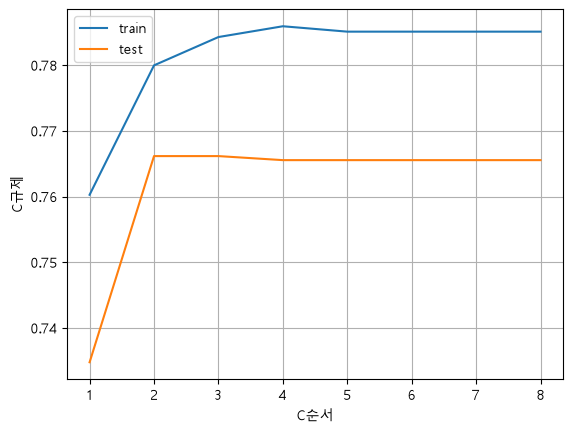

In [7]:
# C의 규제 선그래프
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [8]:
lr = LogisticRegression(C=0.01,max_iter=1000)
lr.fit(train_scaled,train_label)
print('train 정확도 : ',lr.score(train_scaled,train_label))
print('test 정확도 : ',lr.score(test_scaled,test_label))

train 정확도 :  0.7799671592775042
test 정확도 :  0.7661538461538462


In [9]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
ex1 = expit(decisions)  # 이진분류 : expit, 다중분류 : softmax
np.round(ex1,decimals=3)

array([0.974, 0.597, 0.932, 0.949, 0.967])

In [10]:
# 레드와인, 화이트와인을 분류하는 알고리즘을 구현하시오.
# LogisticRegression - 리지규제를 사용해서 구현 p1113_04.ipynb
# SGDClassifier - 반복300회해서 구현 p1113_05.ipynb
# 2가지 모델을 사용해서 구현하시오.